# 18. Sensitivity analysis and uncertainty budgets

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 3, 4 and 12

**Reading:** GUM, clause 5.1 · Saltelli et al., *Global Sensitivity
Analysis: The Primer* · Coleman & Steele, *Experimentation, Validation, and
Uncertainty Analysis for Engineers*

An uncertainty budget does two jobs. It gives the uncertainty of the
result, and it tells the experimenter or designer where the uncertainty
comes from, and therefore what to improve, measure more carefully, or
stop worrying about. The second job is *sensitivity analysis*, and it is
often the more valuable of the two.

This notebook

1. distinguishes sensitivity, uncertainty and importance, and introduces
   the normalised (logarithmic) sensitivity coefficient;
2. builds the budget of an orifice flow meter and shows how it changes with
   the operating point;
3. compares the *bottom-up* budget with the *top-down* scatter of repeated
   calibrations, and uses the comparison to find a missing term;
4. introduces variance-based (Sobol) sensitivity indices, which remain
   valid when the model is nonlinear and the inputs very uncertain;
5. applies them to the time to corrosion of steel in concrete, a problem
   with large, skewed input uncertainties;
6. separates variability from lack of knowledge with nested Monte Carlo;
7. closes with the uncertainty that no input distribution represents: the
   error of the model itself.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import erfinv

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(14)

## 18.1 Sensitivity, uncertainty, importance

For a model $y = f(x_1, \dots, x_n)$, three different numbers describe the
role of input $x_i$.

* The **sensitivity coefficient** $c_i = \partial f/\partial x_i$: how much
  the output changes per unit change of the input. It is a property of the
  model at the operating point and has units.
* The **normalised sensitivity**, or elasticity,

  $$ E_i = \frac{\partial f}{\partial x_i}\,\frac{x_i}{f} = \frac{\partial \ln f}{\partial \ln x_i} , $$

  the percentage change of the output per percentage change of the input.
  It is dimensionless, so inputs measured in different units can be
  compared. For a product of powers $f = C x_1^{p_1}x_2^{p_2}\cdots$ the
  elasticities are simply the exponents. Zhang *et al.* (2019) use this
  coefficient, under the name relative sensitivity, to rank error sources in
  a precision measuring machine.
* The **importance**, or contribution to the output uncertainty,
  $|c_i|\,u_i$, or as a relative contribution $|E_i|\,u_i/|x_i|$. Its square,
  as a fraction of $u_y^2$, is the share of the variance in the budget of
  Chapter 3.

A large sensitivity does not make an input important if it is known very
precisely, and a small sensitivity does not make it negligible if it is
poorly known. Sensitivity tells us which inputs *would* matter; importance
tells us which ones *do*, given what we currently know. The first guides
design; the second guides where to spend effort.

(Normalised sensitivities are not useful when the output is close to zero,
for instance when $f$ is itself an error or a difference of nearly equal
quantities. Use the plain coefficients $c_i$ then.)

## 18.2 Example: the discharge coefficient of an orifice meter

An orifice plate in a pipe measures flow from the pressure drop across it.
Before use, the meter is calibrated: water flows through it, the mass flow
rate $\dot m$ is measured independently (by weighing the water collected),
and the discharge coefficient $C$ is computed from

$$ C = \frac{\dot m\,\sqrt{1 - \beta^4}}{\tfrac{\pi}{4}\,d^2\sqrt{2\,\rho\,\Delta P}} , \qquad \beta = \frac{d}{D} , $$

with $d$ the orifice diameter, $D$ the pipe diameter, $\rho$ the water
density and $\Delta P$ the measured pressure difference. The NIST/SEMATECH
e-Handbook uses this equation as its example of propagation of error for
many variables. Typical values of $C$ for a sharp-edged orifice are around
0.6.

The elasticities follow from the logarithmic derivative. Writing
$\ln C = \ln\dot m + \tfrac12\ln(1 - \beta^4) - 2\ln d - \tfrac12\ln\rho - \tfrac12\ln\Delta P + \text{const}$
and using $\partial\ln(1-\beta^4)/\partial\ln d = -4\beta^4/(1-\beta^4)$,

$$ E_{\dot m} = 1, \quad E_\rho = E_{\Delta P} = -\tfrac12, \quad
   E_d = -2 - \frac{2\beta^4}{1-\beta^4}, \quad E_D = +\frac{2\beta^4}{1-\beta^4} . $$

The pipe diameter enters only through $\beta$, and its sensitivity grows
rapidly with $\beta$.

In [2]:
K = np.pi / 4 * np.sqrt(2)

def discharge_coefficient(m, d, D, rho, dP):
    beta = d / D
    return m * np.sqrt(1 - beta**4) / (K * d**2 * np.sqrt(rho * dP))

def mass_flow(C, d, D, rho, dP):
    """Inverse relation, used to build consistent test data."""
    beta = d / D
    return C / np.sqrt(1 - beta**4) * K * d**2 * np.sqrt(rho * dP)

names = ["m", "d", "D", "rho", "dP"]
labels = {"m": r"$\dot m$", "d": "$d$", "D": "$D$", "rho": r"$\rho$", "dP": r"$\Delta P$"}
C_nom, D_pipe, rho_w, dP_nom = 0.606, 0.100, 998.2, 25.0e3        # -, m, kg/m^3, Pa
rel_u = dict(m=0.0025, d=0.0002, D=0.0020, rho=0.0005, dP=0.0030)  # relative standard uncertainties

def operating_point(beta):
    d = beta * D_pipe
    x = np.array([mass_flow(C_nom, d, D_pipe, rho_w, dP_nom), d, D_pipe, rho_w, dP_nom])
    u = x * np.array([rel_u[k] for k in names])
    return x, u

x05, u05 = operating_point(0.5)
rows, C05, uC05 = ep.budget(discharge_coefficient, x05, u05, names=names)
print(f"beta = 0.5:  m = {x05[0]:.3f} kg/s,  C = {ep.format_result(C05, uC05)}")
print(ep.format_budget(rows, C05, uC05))
print("\nelasticities:", dict(zip(names, np.round(ep.elasticities(discharge_coefficient, x05), 3))))

beta = 0.5:  m = 8.682 kg/s,  C = 0.6060 ± 0.0018
input             value           u    rel. u        |c| u    share
-------------------------------------------------------------------
m                8.6818       0.022     0.25%      0.00151    70.9%
d                  0.05       1e-05     0.02%     0.000259     2.1%
D                   0.1      0.0002     0.20%     0.000162     0.8%
rho               998.2         0.5     0.05%     0.000152     0.7%
dP                25000          75     0.30%     0.000909    25.5%
-------------------------------------------------------------------
output            0.606      0.0018     0.30%

elasticities: {'m': np.float64(1.0), 'd': np.float64(-2.133), 'D': np.float64(0.133), 'rho': np.float64(-0.5), 'dP': np.float64(-0.5)}


At $\beta = 0.5$ the mass flow rate dominates, the pressure difference
follows, and the pipe diameter, despite the largest relative uncertainty
among the dimensions (0.2 %), contributes almost nothing because its
elasticity is only 0.13. Its uncertainty is unimportant here, though it
is not small.

The same budget at other values of $\beta$:

In [3]:
betas = np.linspace(0.2, 0.8, 61)
E = np.array([ep.elasticities(discharge_coefficient, operating_point(b)[0]) for b in betas])
shares = {}
for b in (0.5, 0.75):
    x, u = operating_point(b)
    r_, Cb, uCb = ep.budget(discharge_coefficient, x, u, names=names)
    shares[b] = np.array([row["variance_fraction"] for row in r_])
    print(f"beta = {b}: relative u(C) = {uCb / Cb:.3%};  shares: "
          + ", ".join(f"{k} {s:.0%}" for k, s in zip(names, shares[b])))

beta = 0.5: relative u(C) = 0.297%;  shares: m 71%, d 2%, D 1%, rho 1%, dP 26%
beta = 0.75: relative u(C) = 0.351%;  shares: m 51%, d 3%, D 28%, rho 1%, dP 18%


At $\beta = 0.75$ the elasticity of $D$ has risen to 0.93, the pipe
diameter has become the second largest entry in the budget, with 28 % of
the variance (panel (b) of the figure below), and the overall uncertainty
has risen from 0.30 % to 0.35 %. Nothing about the
measurement of $D$ changed; only the operating point did. A budget is valid
for one operating point, and it should be recomputed, not reused, when the
conditions change.

## 18.3 Bottom-up and top-down

The budget above is *bottom-up*: the uncertainty of the result is
assembled from the uncertainties of its inputs through the model. The
NIST/SEMATECH e-Handbook contrasts this with the *top-down* approach, in
which the whole measurement is repeated and the uncertainty is read from
the scatter of the final results. Top-down captures effects that the
bottom-up model left out, correlations nobody suspected, and disturbances
that act on the result rather than on the inputs; bottom-up explains where
the uncertainty comes from and covers the systematic errors that repetition
cannot reveal. The two are complementary, and their comparison is a
powerful test of the budget.

To compare them, the bottom-up budget must first be split into the part
that changes from one repetition to the next and the part that does not.
For a calibration rig:

| Input | Varies between runs (random) | Same in every run (systematic) |
|---|---|---|
| $\dot m$ | 0.15 % (weighing, timing) | 0.20 % (scale calibration) |
| $\Delta P$ | 0.20 % (fluctuation, averaging) | 0.20 % (transducer calibration) |
| $\rho$ | 0.02 % (temperature) | 0.05 % |
| $d$, $D$ | none | 0.02 %, 0.20 % |

With the elasticities of 18.2, the predicted run-to-run scatter of $C$ is
$\sqrt{0.15^2 + (0.5\times0.20)^2 + (0.5\times0.02)^2}\,\% = 0.18\,\%$.

We now simulate a calibration campaign of 5 days with 4 runs per day. The
simulation contains one effect that the budget does not: the installation
is slightly disturbed each time the rig is reassembled (gasket position,
upstream flow profile), which changes the *actual* discharge coefficient
by about 0.25 % from day to day. It acts on the result, not on any
measured input, which is exactly the kind of disturbance the e-Handbook
warns about.

In [4]:
beta_cal = 0.5
d_true = beta_cal * D_pipe
rand = dict(m=0.0015, dP=0.0020, rho=0.0002)
syst = dict(m=0.0020, dP=0.0020, rho=0.0005, d=0.0002, D=0.0020)
E05 = dict(zip(names, ep.elasticities(discharge_coefficient, operating_point(beta_cal)[0])))
u_run_pred = np.sqrt(sum((E05[k] * rand[k])**2 for k in rand))
u_sys_pred = np.sqrt(sum((E05[k] * syst[k])**2 for k in syst))
print(f"bottom-up: run-to-run {u_run_pred:.3%}, systematic {u_sys_pred:.3%}")

def campaign(rng, day_sd=0.0025, n_days=5, n_runs=4):
    """Measured C for each run, shape (n_days, n_runs)."""
    s = {k: rng.normal(0, v) for k, v in syst.items()}                  # fixed for the campaign
    C_day = C_nom * (1 + rng.normal(0, day_sd, n_days))                  # actual C, changes per day
    out = np.empty((n_days, n_runs))
    for i in range(n_days):
        dP_true = dP_nom * rng.uniform(0.9, 1.1, n_runs)
        m_true = mass_flow(C_day[i], d_true, D_pipe, rho_w, dP_true)
        m_meas = m_true * (1 + s["m"] + rng.normal(0, rand["m"], n_runs))
        dP_meas = dP_true * (1 + s["dP"] + rng.normal(0, rand["dP"], n_runs))
        rho_meas = rho_w * (1 + s["rho"] + rng.normal(0, rand["rho"], n_runs))
        out[i] = discharge_coefficient(m_meas, d_true * (1 + s["d"]), D_pipe * (1 + s["D"]), rho_meas, dP_meas)
    return out

C_runs = campaign(rng)
rel = C_runs / C_runs.mean() - 1
s_all = rel.std(ddof=1)
s_within = np.sqrt(np.mean(rel.var(axis=1, ddof=1)))
s_daymeans = rel.mean(axis=1).std(ddof=1)
n_runs = C_runs.shape[1]
print(f"top-down: scatter of all 20 runs       {s_all:.3%}   (bottom-up predicts {u_run_pred:.3%})")
print(f"          pooled scatter within days   {s_within:.3%}")
print(f"          scatter of the 5 day means   {s_daymeans:.3%}   (predicted {u_run_pred / np.sqrt(n_runs):.3%})")
chi2 = (rel.size - 1) * s_all**2 / u_run_pred**2
print(f"Birge ratio s/u = {s_all / u_run_pred:.2f};  chi-square = {chi2:.1f} for {rel.size - 1} dof, "
      f"p = {stats.chi2.sf(chi2, rel.size - 1):.4f}")
chi2_days = (C_runs.shape[0] - 1) * s_daymeans**2 / (u_run_pred**2 / n_runs)
print(f"day means against the budget: chi-square = {chi2_days:.1f} for {C_runs.shape[0] - 1} dof, "
      f"p = {stats.chi2.sf(chi2_days, C_runs.shape[0] - 1):.4f}")
s_day_est = np.sqrt(max(s_daymeans**2 - s_within**2 / n_runs, 0))
print(f"estimated day-to-day component: {s_day_est:.3%}   (built into the simulation: 0.25 %)")

bottom-up: run-to-run 0.181%, systematic 0.231%
top-down: scatter of all 20 runs       0.202%   (bottom-up predicts 0.181%)
          pooled scatter within days   0.132%
          scatter of the 5 day means   0.179%   (predicted 0.090%)
Birge ratio s/u = 1.12;  chi-square = 23.7 for 19 dof, p = 0.2087
day means against the budget: chi-square = 15.7 for 4 dof, p = 0.0035
estimated day-to-day component: 0.166%   (built into the simulation: 0.25 %)


Taken as one set of 20 numbers, the runs scatter only a little more than
the budget predicts (Birge ratio $s/u$ = 1.12), and a chi-square test would
let the budget pass ($p = 0.21$). Grouping the runs by day changes the
picture. Within a day they scatter no more than predicted, but the five day
means scatter twice as much as four runs per day can explain, and that is
very unlikely to be chance ($p = 0.003$). A one-way analysis of variance of
this kind turns the disagreement between top-down and bottom-up into an
estimate of the missing component, which can then be entered in the budget.
With only five days the estimate is rough: 0.17 % here, against the 0.25 %
built into the simulation.

Two consequences for the final uncertainty. The day-to-day effect averages
over the 5 days of the calibration, so it enters the uncertainty of the
*calibrated* $C$ as $0.25\,\%/\sqrt 5$. But it applies in full to every
later *use* of the meter after reassembly, so the uncertainty of a flow
measured with this meter must include the whole 0.25 %. The question "which
terms average down?" has to be asked separately for every use of a result.

How often does a campaign reveal the missing term? Repeating the simulated
campaign many times, with and without the day effect:

In [5]:
def tests(day_sd, n=4000):
    """Birge ratio of all runs, and p-value of the day means, for n campaigns."""
    birge_ratio, p_days = np.empty(n), np.empty(n)
    for i in range(n):
        r = campaign(rng, day_sd=day_sd)
        r = r / r.mean() - 1
        birge_ratio[i] = r.std(ddof=1) / u_run_pred
        c2 = (r.shape[0] - 1) * r.mean(axis=1).var(ddof=1) / (u_run_pred**2 / r.shape[1])
        p_days[i] = stats.chi2.sf(c2, r.shape[0] - 1)
    return birge_ratio, p_days

birge_ok, pdays_ok = tests(0.0)
birge_missing, pdays_missing = tests(0.0025)
crit = np.sqrt(stats.chi2.ppf(0.95, 19) / 19)
print(f"95 % critical Birge ratio for 19 dof: {crit:.2f}")
print("                     all 20 runs (Birge)   day means")
print(f"budget complete : flagged in {np.mean(birge_ok > crit):6.1%}            {np.mean(pdays_ok < 0.05):6.1%}   of campaigns")
print(f"term missing    : flagged in {np.mean(birge_missing > crit):6.1%}            {np.mean(pdays_missing < 0.05):6.1%}   of campaigns")

95 % critical Birge ratio for 19 dof: 1.26
                     all 20 runs (Birge)   day means
budget complete : flagged in   5.1%              5.0%   of campaigns
term missing    : flagged in  77.2%             89.9%   of campaigns


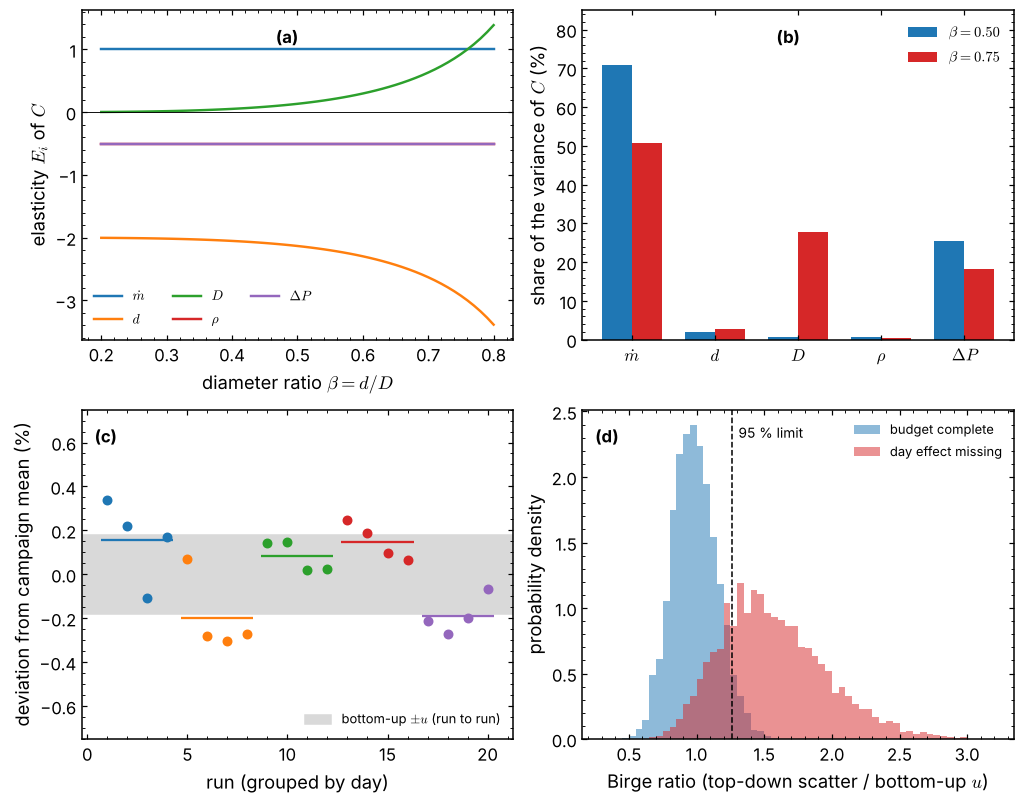

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
for j, k in enumerate(names):
    ax.plot(betas, E[:, j], color=f"C{j}", label=labels[k])
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel(r"diameter ratio $\beta = d/D$"); ax.set_ylabel(r"elasticity $E_i$ of $C$")
ax.legend(loc="lower left", ncol=3, fontsize=9); ep.panel_label(ax, "(a)", x=0.45)

ax = axes[0, 1]
xpos = np.arange(len(names))
ax.bar(xpos - 0.18, 100 * shares[0.5], width=0.36, color="C0", label=r"$\beta = 0.50$")
ax.bar(xpos + 0.18, 100 * shares[0.75], width=0.36, color="C3", label=r"$\beta = 0.75$")
ax.set_xticks(xpos); ax.set_xticklabels([labels[k] for k in names])
ax.tick_params(axis="x", which="minor", bottom=False, top=False)
ax.set_ylabel("share of the variance of $C$ (%)"); ax.set_ylim(0, 85)
ax.legend(loc="upper right"); ep.panel_label(ax, "(b)", y=0.95, x=0.45)

ax = axes[1, 0]
run_index = np.arange(C_runs.size) + 1
for i in range(C_runs.shape[0]):
    idx = run_index[i * n_runs:(i + 1) * n_runs]
    ax.plot(idx, 100 * rel[i], "o", color=f"C{i}")
    ax.hlines(100 * rel[i].mean(), idx[0] - 0.3, idx[-1] + 0.3, color=f"C{i}", lw=1.5)
ax.axhspan(-100 * u_run_pred, 100 * u_run_pred, color="0.85", zorder=0, label=r"bottom-up $\pm u$ (run to run)")
ax.set_xlabel("run (grouped by day)"); ax.set_ylabel("deviation from campaign mean (%)")
ax.set_ylim(-0.75, 0.75); ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(c)", y=0.95)

ax = axes[1, 1]
bins = np.linspace(0.3, 3.2, 59)
ax.hist(birge_ok, bins=bins, density=True, color="C0", alpha=0.5, label="budget complete")
ax.hist(birge_missing, bins=bins, density=True, color="C3", alpha=0.5, label="day effect missing")
ax.axvline(crit, color="k", ls="--", lw=1)
ax.text(crit + 0.05, 2.3, "95 % limit", fontsize=9)
ax.set_xlabel("Birge ratio (top-down scatter / bottom-up $u$)"); ax.set_ylabel("probability density")
ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(d)", y=0.95)
plt.show()

**(a)** Elasticities of $C$ against the diameter ratio; those of $\dot m$,
$\rho$ and $\Delta P$ are constant (the last two coincide at $-1/2$), those
of the two diameters grow with $\beta$. **(b)** The budget at two operating points. **(c)** One simulated
calibration campaign: runs grouped by day, with the day means (lines) and
the run-to-run scatter predicted by the bottom-up budget (band). **(d)**
The Birge ratio over many simulated campaigns: with a complete budget it
exceeds the 95 % limit in 5 % of campaigns, as it should; with the day
effect missing, in about three quarters of them.

Testing the day means against the budget catches the missing term more
often than the overall scatter does, because it looks where the effect is.
Even so, no single campaign is certain to find it. A budget that passes the
top-down test has not been proven complete; one that fails it has been
proven incomplete. And the test is only as good as the grouping: an effect
that changes between days can only be found if the campaign spans several
days.

## 18.4 Global sensitivity: variance-based indices

Derivatives describe the model near one point. When input uncertainties
are large, so that the model is not linear over their range (Section 12.3),
or when inputs interact, the derivatives at the nominal point can misstate
the importance of an input. A global measure asks a different question:
*if we knew $x_i$ exactly, by how much would the output variance fall, on
average?*

The answer is the **first-order Sobol index**

$$ S_i = \frac{\operatorname{Var}\bigl(\mathrm E[\,y \mid x_i\,]\bigr)}{\operatorname{Var}(y)} , $$

the fraction of the output variance explained by $x_i$ alone. Its partner,
the **total index**

$$ S_{Ti} = \frac{\mathrm E\bigl[\operatorname{Var}(\,y \mid x_{\sim i}\,)\bigr]}{\operatorname{Var}(y)} , $$

is the fraction of the variance that would *remain* if every input except
$x_i$ were known; it includes all interactions involving $x_i$. Three
properties make the indices easy to read:

* for a linear model with independent inputs, $S_i = S_{Ti}$ = the share of
  the variance in the ordinary budget;
* $\sum_i S_i \le 1$, and the shortfall $1 - \sum_i S_i$ is the part of the
  variance due to interactions;
* $S_{Ti} \approx 0$ means that the input can be fixed at any value in its
  range without affecting the output: it is truly negligible.

The indices are estimated by Monte Carlo with two independent input
samples $\mathsf A$ and $\mathsf B$ and, for each input, a third sample in
which only column $i$ of $\mathsf A$ is replaced by that of $\mathsf B$
(estimators of Saltelli 2010 and Jansen 1999, implemented in
`ep.sobol_indices`). The cost is $N(k+2)$ model evaluations for $k$ inputs.

**Validation.** The Ishigami function,
$f = \sin x_1 + 7\sin^2 x_2 + 0.1\,x_3^4\sin x_1$ with all $x_i$ uniform on
$[-\pi, \pi]$, is the standard test case: its indices are known exactly, and
$x_3$ has no effect on its own ($S_3 = 0$) but a large one through its
interaction with $x_1$.

In [7]:
sample_ishigami = lambda n, rng: rng.uniform(-np.pi, np.pi, (n, 3))
res = ep.sobol_indices(ep.ishigami, sample_ishigami, n=2**15, rng=rng)
S_ex, ST_ex = ep.ishigami_exact()
print("        S (estimate)      S (exact)   ST (estimate)     ST (exact)")
for i in range(3):
    print(f"x{i + 1}   {res['S'][i]:6.3f} +/- {res['S_se'][i]:.3f}    {S_ex[i]:6.3f}    "
          f"{res['ST'][i]:6.3f} +/- {res['ST_se'][i]:.3f}    {ST_ex[i]:6.3f}")
print(f"model evaluations: {res['n_evals']}")

        S (estimate)      S (exact)   ST (estimate)     ST (exact)
x1    0.313 +/- 0.007     0.314     0.552 +/- 0.008     0.558
x2    0.439 +/- 0.008     0.442     0.438 +/- 0.004     0.442
x3   -0.010 +/- 0.006     0.000     0.241 +/- 0.003     0.244
model evaluations: 163840


The estimates agree with the exact values to within about two bootstrap
standard errors (a small negative estimate of an index that is exactly zero
is ordinary sampling noise). The local derivative of $f$ with respect to $x_3$ is zero at the
nominal point $x = 0$, and a derivative-based budget would declare $x_3$
irrelevant; its total index of 0.24 says that a quarter of the variance
would remain if it were the only unknown.

## 18.5 Example: time to corrosion of steel in concrete

Steel reinforcement in concrete exposed to sea water or de-icing salt
starts to corrode when the chloride concentration at the depth of the
steel reaches a critical value. With chloride diffusing from the surface
according to Fick's second law, the concentration at depth $x$ after time
$t$ is $C(x,t) = C_s\bigl[1 - \operatorname{erf}\bigl(x/2\sqrt{Dt}\bigr)\bigr]$,
and setting $C = C_\text{cr}$ gives the time to corrosion initiation,

$$ t_\text{i} = \frac{x^2}{4D}\,\Bigl[\operatorname{erf}^{-1}\Bigl(1 - \frac{C_\text{cr}}{C_s}\Bigr)\Bigr]^{-2} . $$

All four inputs vary considerably from one structure, or one location in a
structure, to another: the cover depth $x$ (construction tolerance), the
chloride diffusivity $D$ (material variability; lognormal distributions
are common, as Mahadevan and Sarkar (2009) note), the surface concentration
$C_s$ (exposure) and the critical concentration $C_\text{cr}$. We use
illustrative values, not design values:

| Input | Distribution | Mean | Coefficient of variation |
|---|---|---|---|
| cover depth $x$ | normal | 50 mm | 16 % |
| diffusivity $D$ | lognormal | 30 mm²/year | 50 % |
| surface concentration $C_s$ | lognormal | 3.5 | 25 % |
| critical concentration $C_\text{cr}$ | lognormal | 0.9 | 25 % |

($C_s$ and $C_\text{cr}$ in the same units, for example kg of chloride per
m³ of concrete; only their ratio enters.) With uncertainties this large the
linear law is not to be trusted (output relative uncertainty far above
10 %), and the distribution of $t_\text{i}$ is strongly skewed. Since
$t_\text{i}$ becomes infinite when $C_\text{cr} \ge C_s$, we cap it at 1000
years, which for engineering purposes means "never", and analyse
$\ln t_\text{i}$.

In [8]:
def lognormal_params(mean, cov):
    s = np.sqrt(np.log(1 + cov**2))
    return np.log(mean) - s**2 / 2, s

par = dict(x=(50.0, 8.0), D=lognormal_params(30.0, 0.5),
           Cs=lognormal_params(3.5, 0.25), Ccr=lognormal_params(0.9, 0.25))

def t_init(x, D, Cs, Ccr):
    ratio = np.minimum(Ccr / Cs, 1 - 1e-12)
    t = x**2 / (4 * D * erfinv(1 - ratio)**2)
    return np.minimum(t, 1000.0)

def sample_corrosion(n, rng, mu_lnD=par["D"][0], s_lnD=par["D"][1]):
    return np.column_stack([np.maximum(rng.normal(*par["x"], n), 5.0),
                            rng.lognormal(mu_lnD, s_lnD, n),
                            rng.lognormal(*par["Cs"], n),
                            rng.lognormal(*par["Ccr"], n)])

X = sample_corrosion(400_000, rng)
t = t_init(*X.T)
q05, q50, q95 = np.quantile(t, [0.05, 0.5, 0.95])
t_nom = t_init(50.0, 30.0, 3.5, 0.9)
print(f"t_i at the mean inputs: {t_nom:.1f} years")
print(f"distribution of t_i: median {q50:.1f} years, 90 % interval {q05:.1f} to {q95:.0f} years")
print(f"P(t_i < 50 years) = {np.mean(t < 50):.3f}")

# local budget for ln t_i, using the standard deviation of each input
ln_t = lambda x, D, Cs, Ccr: np.log(t_init(x, D, Cs, Ccr))
means = np.array([50.0, 30.0, 3.5, 0.9])
sds = np.array([8.0, 15.0, 0.875, 0.225])
rows_t, lt0, u_lt = ep.budget(ln_t, means, sds, names=["x", "D", "Cs", "Ccr"])
local_share = np.array([r["variance_fraction"] for r in rows_t])
print(f"\nlinear law for ln t_i: {lt0:.3f} +/- {u_lt:.3f};  Monte Carlo: {np.log(t).mean():.3f} +/- {np.log(t).std():.3f}")

res_t = ep.sobol_indices(ln_t, sample_corrosion, n=2**15, rng=rng)
print("\ninput   local share   S (first order)     ST (total)")
for i, k in enumerate(["x", "D", "Cs", "Ccr"]):
    print(f"{k:5s}     {local_share[i]:5.2f}       {res_t['S'][i]:5.2f} +/- {res_t['S_se'][i]:.2f}    "
          f"{res_t['ST'][i]:6.3f} +/- {res_t['ST_se'][i]:.3f}")
print(f"sum of first-order indices: {res_t['S'].sum():.2f} +/- {np.sqrt(np.sum(res_t['S_se']**2)):.2f}")

t_i at the mean inputs: 32.4 years
distribution of t_i: median 36.9 years, 90 % interval 11.9 to 124 years
P(t_i < 50 years) = 0.667

linear law for ln t_i: 3.480 +/- 0.706;  Monte Carlo: 3.626 +/- 0.719



input   local share   S (first order)     ST (total)
x          0.21        0.22 +/- 0.02     0.214 +/- 0.002
D          0.50        0.42 +/- 0.03     0.433 +/- 0.004
Cs         0.15        0.19 +/- 0.02     0.183 +/- 0.002
Ccr        0.15        0.20 +/- 0.02     0.183 +/- 0.002
sum of first-order indices: 1.03 +/- 0.04


The diffusivity accounts for about 40 % of the variance of
$\ln t_\text{i}$, and the cover depth and the two concentrations for about
20 % each. The local budget gets the order right but not the proportions:
it gives the diffusivity half the variance and the concentrations 15 %
each. Both errors come from linearising over large uncertainties. A
diffusivity with a coefficient of variation of 50 % does not have
$\operatorname{sd}(\ln D) = 0.50$, as the derivative at the mean implies,
but 0.47; and the concentrations act through
$\operatorname{erf}^{-1}(1 - C_\text{cr}/C_s)$, which is curved over the
range of their ratio.

The total indices equal the first-order ones within their uncertainty, and
the first-order indices add up to one: there are no appreciable
interactions. This is no accident. Taking the logarithm turned the model
into a sum, $\ln t_\text{i} = 2\ln x - \ln D - 2\ln\operatorname{erf}^{-1}(\cdot) + \text{const}$,
of a term in $x$, a term in $D$ and a term in the concentration ratio
(the remaining interaction between $C_s$ and $C_\text{cr}$ is weak because
each is uncertain by only 25 %). Choosing the output variable is part of
the analysis: for $t_\text{i}$ itself the same inputs interact strongly
(Exercise 3).

For decisions the ranking is what counts. Reducing the uncertainty of the
diffusivity (more cores, better tests) would do most to sharpen the
prediction. The cover depth, the one input the contractor controls,
contributes a fifth of the variance; its *mean* value matters even more,
through the factor $x^2$ in the result.

## 18.6 Variability and lack of knowledge

The input distributions above describe *variability*: real differences
between locations or structures. They do not shrink with more data; more
cores would only describe the variability better. This is **aleatory**
uncertainty. Our *knowledge* of those distributions is itself uncertain:
suppose the distribution of $D$ was estimated from eight cores. The mean and
spread of $\ln D$ are then only estimates, and that uncertainty does shrink
with more data. This is **epistemic** uncertainty. Mahadevan and Sarkar
(2009) recommend treating the two separately with a **nested** Monte Carlo
calculation:

* in the outer loop, draw plausible values of the uncertain distribution
  parameters (here the mean and standard deviation of $\ln D$, from their
  distribution given the eight cores);
* in the inner loop, propagate the variability for those parameters and
  compute the quantity of interest, here the probability
  $P_f = P(t_\text{i} < 50\ \text{years})$, or the whole distribution of
  $t_\text{i}$.

The result is not one probability but a distribution of probabilities,
whose width says how much the answer depends on our limited data.

For normally distributed $\ln D$ with unknown mean and variance, the
standard choice is: $\sigma^2 = (n-1)s^2/\chi^2_{n-1}$, then
$\mu \sim N(\bar z, \sigma^2/n)$, where $\bar z$ and $s$ are the mean and
standard deviation of the $n$ observed values of $\ln D$.

In [9]:
cores = rng.lognormal(*par["D"], 8)                    # eight measured diffusivities, mm^2/year
z = np.log(cores)
zbar, s_z, n_c = z.mean(), z.std(ddof=1), z.size
print("measured D (mm^2/year):", np.round(np.sort(cores), 1))
print(f"ln D: mean {zbar:.3f}, standard deviation {s_z:.3f}   (true {par['D'][0]:.3f}, {par['D'][1]:.3f})")

t_grid = np.logspace(0, 3, 200)
n_outer, n_inner = 400, 20_000
Pf = np.empty(n_outer)
cdfs = np.empty((n_outer, t_grid.size))
for j in range(n_outer):
    sigma = np.sqrt((n_c - 1) * s_z**2 / rng.chisquare(n_c - 1))
    mu = rng.normal(zbar, sigma / np.sqrt(n_c))
    tt = np.sort(t_init(*sample_corrosion(n_inner, rng, mu, sigma).T))
    Pf[j] = np.mean(tt < 50)
    cdfs[j] = np.searchsorted(tt, t_grid) / n_inner

t_plug = np.sort(t_init(*sample_corrosion(200_000, rng, zbar, s_z).T))
cdf_plug = np.searchsorted(t_plug, t_grid) / t_plug.size
cdf_true = np.searchsorted(np.sort(t), t_grid) / t.size
print(f"\nP(t_i < 50 y) with the true distribution of D : {np.mean(t < 50):.3f}")
print(f"plug-in estimate (sample mean and sd)          : {np.mean(t_plug < 50):.3f}")
print(f"nested Monte Carlo: median {np.median(Pf):.3f}, 90 % interval {np.quantile(Pf, 0.05):.3f} to {np.quantile(Pf, 0.95):.3f}")

measured D (mm^2/year): [18.2 19.4 23.9 28.  33.2 49.7 52.7 53.9]
ln D: mean 3.466, standard deviation 0.445   (true 3.290, 0.472)



P(t_i < 50 y) with the true distribution of D : 0.667
plug-in estimate (sample mean and sd)          : 0.757
nested Monte Carlo: median 0.752, 90 % interval 0.582 to 0.857


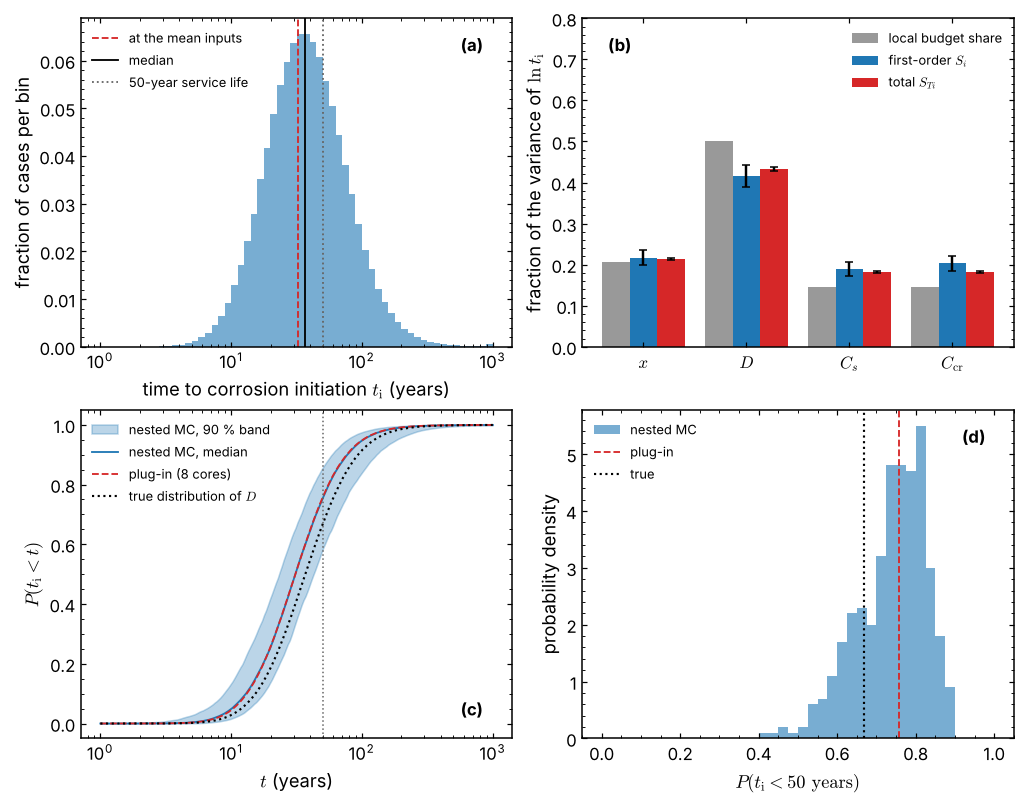

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
ax.hist(t, bins=np.logspace(0, 3, 61), density=False, weights=np.full(t.size, 1 / t.size), color="C0", alpha=0.6)
ax.axvline(t_nom, color="C3", ls="--", lw=1.2, label="at the mean inputs")
ax.axvline(q50, color="k", lw=1.2, label="median")
ax.axvline(50, color="0.4", ls=":", lw=1.2, label="50-year service life")
ax.set_xscale("log"); ax.set_xlabel("time to corrosion initiation $t_\\mathrm{i}$ (years)")
ax.set_ylabel("fraction of cases per bin")
ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(a)", x=0.88)

ax = axes[0, 1]
lab = ["$x$", "$D$", "$C_s$", r"$C_\mathrm{cr}$"]
xp = np.arange(4)
ax.bar(xp - 0.27, local_share, width=0.27, color="0.6", label="local budget share")
ax.bar(xp, res_t["S"], width=0.27, yerr=res_t["S_se"], color="C0", label="first-order $S_i$")
ax.bar(xp + 0.27, res_t["ST"], width=0.27, yerr=res_t["ST_se"], color="C3", label="total $S_{Ti}$")
ax.set_xticks(xp); ax.set_xticklabels(lab)
ax.tick_params(axis="x", which="minor", bottom=False, top=False)
ax.set_ylabel(r"fraction of the variance of $\ln t_\mathrm{i}$"); ax.set_ylim(0, 0.8)
ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(b)", x=0.06)

ax = axes[1, 0]
lo, hi = np.quantile(cdfs, [0.05, 0.95], axis=0)
ax.fill_between(t_grid, lo, hi, color="C0", alpha=0.3, label="nested MC, 90 % band")
ax.plot(t_grid, np.median(cdfs, axis=0), "C0", lw=1.2, label="nested MC, median")
ax.plot(t_grid, cdf_plug, "C3--", lw=1.2, label="plug-in (8 cores)")
ax.plot(t_grid, cdf_true, "k:", lw=1.4, label="true distribution of $D$")
ax.axvline(50, color="0.4", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("$t$ (years)"); ax.set_ylabel(r"$P(t_\mathrm{i} < t)$")
ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(c)", x=0.88, y=0.12)

ax = axes[1, 1]
ax.hist(Pf, bins=np.linspace(0, 1, 41), density=True, color="C0", alpha=0.6, label="nested MC")
ax.axvline(np.mean(t_plug < 50), color="C3", ls="--", lw=1.2, label="plug-in")
ax.axvline(np.mean(t < 50), color="k", ls=":", lw=1.4, label="true")
ax.set_xlabel(r"$P(t_\mathrm{i} < 50\ \mathrm{years})$"); ax.set_ylabel("probability density")
ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(d)", x=0.88)
plt.show()

**(a)** The distribution of the initiation time spans two orders of
magnitude; the value computed at the mean inputs is not its median.
**(b)** Local budget shares against first-order and total Sobol indices
for $\ln t_\text{i}$. **(c)** Distribution function of $t_\text{i}$: the
band from the nested calculation contains the true curve, while the
plug-in curve, which treats eight cores as perfect knowledge, is a single
line that happens to be wrong. **(d)** The probability of corrosion within
50 years is itself uncertain, and with eight cores substantially so.

The practical message is that a probability computed from sparse data
should be reported with its own uncertainty. The nested calculation also
tells the engineer what more data would buy: repeating it with 30 cores
instead of 8 narrows the band in panel (c), while no amount of data narrows
the spread in panel (a), which is real variability.

## 18.7 The error of the model itself

Every budget so far has propagated the uncertainty of the *inputs* through
a model assumed to be exact. Mahadevan and Sarkar (2009) write the
difference between a prediction and an observation as a sum of separate
errors,

$$ \varepsilon_\text{obs} = \varepsilon_\text{num} + \varepsilon_\text{model} - \varepsilon_\text{exp} , $$

numerical error (discretisation, sampling, round-off), model-form error,
and measurement error, and point out that the first and last can be
estimated (convergence studies, Section 12.4; experimental budgets, this
notebook), so that model-form error is what remains when a prediction is
compared with a validation experiment.

Model-form error is the hardest term, for three reasons. It is invisible to
any propagation of input uncertainty; it does not average out; and it is
usually larger than everything else in the budget. In the falling-sphere
example ([Chapter 21](../part5_examples/21_falling_sphere_viscosity.ipynb)) the neglected
wall correction was fourteen times the complete input budget. In the
corrosion model it would take the form of constant diffusivity (real
concrete becomes less permeable as it ages), constant surface
concentration, and the neglect of cracks, any of which can move the
predicted initiation time by more than the whole spread of panel (a).

What can be done is limited but important:

* compare the model with independent data that were not used to fit it, and
  treat the discrepancy, in units of the combined uncertainty, as a
  validation metric (Section 1.6);
* where several models are plausible, run all of them and report the
  spread of their predictions alongside the parameter uncertainty;
* state the model assumptions next to the result, so that a reader knows
  what the uncertainty does not cover.

## Summary

* Sensitivity ($c_i$, or the dimensionless $E_i$) is a property of the
  model at an operating point; importance ($|c_i|u_i$) combines it with
  what we know. Budgets must be recomputed when the operating point changes.
* Compare bottom-up budgets with top-down scatter. Agreement is weak
  evidence of completeness; disagreement is strong evidence of a missing
  term, and grouping the data (by day, operator, instrument) can locate it.
* Sobol indices extend the budget to nonlinear models and large
  uncertainties: $S_i$ is what would be gained by knowing $x_i$, and
  $S_{Ti}$ what would remain unknown without it.
* Keep variability and lack of knowledge apart; a probability computed from
  sparse data has an uncertainty of its own.
* No propagation captures the error of the model; only validation against
  independent data can.

## References

* H. W. Coleman and W. G. Steele, *Experimentation, Validation, and
  Uncertainty Analysis for Engineers*, 4th ed. (Wiley, 2018).
* JCGM 100:2008, *Evaluation of measurement data — Guide to the expression
  of uncertainty in measurement* (GUM), clause 5.1.
* A. Saltelli, M. Ratto, T. Andres, F. Campolongo, J. Cariboni, D. Gatelli,
  M. Saisana and S. Tarantola, *Global Sensitivity Analysis: The Primer*
  (Wiley, 2008).
* NIST/SEMATECH e-Handbook of Statistical Methods, Section 2.5.5,
  "Propagation of error considerations" (top-down and bottom-up; the
  discharge-coefficient example).
* H. H. Ku, "Notes on the use of propagation of error formulas", *J. Res.
  Natl. Bur. Stand.* **70C**, 263 (1966).
* S. Mahadevan and S. Sarkar, *Uncertainty Analysis Methods*, report
  CBP-TR-2009-002, Vanderbilt University (2009).
* M. Zhang, Y. Liu, C. Sun, X. Wang and J. Tan, "Measurements error
  propagation and its sensitivity analysis in the aero-engine multistage
  rotor assembling process", *Rev. Sci. Instrum.* **90**, 115003 (2019).
* I. M. Sobol', "Global sensitivity indices for nonlinear mathematical
  models and their Monte Carlo estimates", *Math. Comput. Simul.* **55**,
  271 (2001).
* A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto and
  S. Tarantola, "Variance based sensitivity analysis of model output.
  Design and estimator for the total sensitivity index", *Comput. Phys.
  Commun.* **181**, 259 (2010).
* M. J. W. Jansen, "Analysis of variance designs for model output",
  *Comput. Phys. Commun.* **117**, 35 (1999).
* T. Ishigami and T. Homma, "An importance quantification technique in
  uncertainty analysis for computer models", *Proc. ISUMA '90*, 398 (1990).

## Exercises

1. In the orifice example, the two diameters are measured with the same
   bore gauge, whose scale error is common to both. Model this as a common
   factor $\lambda$ multiplying $d$ and $D$. What is the elasticity of $C$
   with respect to $\lambda$, and why does it not depend on $\beta$?
2. Repeat the calibration campaign with 10 days of 2 runs instead of 5 days
   of 4. How does the probability of detecting the day effect change? Which
   design estimates the day-to-day component better?
3. Compute the Sobol indices of $t_\text{i}$ itself (not its logarithm),
   capped at 200 years. Why do they differ from those of $\ln t_\text{i}$?
   Which output is the right one for a decision about the service life?
4. Use the Sobol machinery to find the first-order index of the
   *combination* $C_\text{cr}/C_s$ (treat the ratio as a single input).
   Compare it with $S_{C_s} + S_{C_\text{cr}}$ and interpret the difference.
5. Repeat the nested calculation of Section 18.6 with 30 cores. By how much does the
   90 % interval of $P(t_\text{i} < 50\ \text{years})$ shrink? What would
   you tell the owner of the structure about the value of more testing?

---

**Previous:** [17. Correlated data and block averaging](17_correlated_data_and_block_averaging.ipynb) &nbsp;·&nbsp; **Next:** [19. Numerical error](19_numerical_error.ipynb)